In [46]:
%load_ext autoreload
%autoreload 2


import optuna
import pandas as pd

import matplotlib.pyplot as plt

from TrailPredictor.dataset import Dataset
from TrailPredictor.modeling.heart_rate import (
    REFERENCE_CUTS,
    HeartRateConfig,
    cuts_to_zones,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [47]:
dataset = Dataset.load(min_distance=40, max_distance=100, segment_width=500)
dataset.target = "pace"  # set before building the model: the result is saved per target

config = HeartRateConfig(
    n_trials=50,
    max_trials_factor=20,
    zone_counts=(2, 3, 4, 5, 6),
    seed=42,
    n_splits=5,
)
# reloads the saved trials of this exact configuration, if any
model = dataset.modeling.heart_rate(config)

# plotter = dataset.plot

Result file /home/caill/project/strava/data/computed/models/base/pace_n_splits_5.csv does not exist. Please run the model.
Result file /home/caill/project/strava/data/computed/models/base/pace_n_splits_5.csv does not exist. Please run the model.


## Heart-rate zone cuts optimisation (Optuna)

Only the zone definition changes from one trial to the next: for N zones, Optuna suggests N-1
increasing cuts, the zones are rebuilt on a copy of the dataset (`Dataset.with_heart_rate_zones`),
then the pipeline is evaluated with `GroupKFold(config.n_splits)` grouped by `activity_id`.
One study per N in `config.zone_counts`, then N is chosen with the 1-SE rule.

The trials are saved under `data/computed/models/heart_rate/<target>/<config hash>.csv`
(with the configuration as JSON next to it) and reloaded when the same `HeartRateConfig` is used again.

In [50]:
# Run the studies only when no result is saved for this configuration.
# The Optuna studies are not saved: `studies` is empty after a reload.
studies = model.optimize_zones() if model.result is None else {}

[I 2026-11-15 22:19:12,455] A new study created in memory with name: heart_rate_zones_2


[I 2026-11-15 22:19:13,051] Trial 0 finished with value: 2.0781404895496243 and parameters: {'c1': 139}. Best is trial 0 with value: 2.0781404895496243.
[I 2026-11-15 22:19:13,475] Trial 1 finished with value: 1.9905060029527157 and parameters: {'c1': 168}. Best is trial 1 with value: 1.9905060029527157.
[I 2026-11-15 22:19:13,826] Trial 2 finished with value: 1.923227481012042 and parameters: {'c1': 157}. Best is trial 2 with value: 1.923227481012042.
[I 2026-11-15 22:19:14,168] Trial 3 finished with value: 1.942932449356308 and parameters: {'c1': 150}. Best is trial 2 with value: 1.923227481012042.
[I 2026-11-15 22:19:14,532] Trial 4 finished with value: 2.1348126992948346 and parameters: {'c1': 127}. Best is trial 2 with value: 1.923227481012042.
[I 2026-11-15 22:19:14,853] Trial 5 finished with value: 2.1348126992948346 and parameters: {'c1': 127}. Best is trial 2 with value: 1.923227481012042.
[I 2026-11-15 22:19:15,167] Trial 6 finished with value: 2.130569018215885 and parameter

Result saved to /home/caill/project/strava/data/computed/models/heart_rate/pace_first_cur_range_120_170_gap_range_4_30_max_last_cut_188_max_trials_factor_20_n_splits_5_n_trials_50_zone_counts_2_3_4_5_6.csv


In [51]:
# Reference: current HEART_RATE_ZONES cuts, as contiguous zones from 0 to 250 bpm
REFERENCE_RMSE, REFERENCE_SE = model.evaluate_cuts_zones(REFERENCE_CUTS)
model.reference_rmse = REFERENCE_RMSE  # reference line of model.plot

f"RMSE de référence (HEART_RATE_ZONES) : {REFERENCE_RMSE:.4f} ± {REFERENCE_SE:.4f}"

'RMSE de référence (HEART_RATE_ZONES) : 1.9194 ± 0.2747'

In [52]:
# Summary built from the saved trials (model.result), so it also works after a reload
trial_counts = pd.crosstab(model.result["n_zones"], model.result["state"]).reindex(
    columns=["COMPLETE", "PRUNED"], fill_value=0
)
summary = model.plot.best_trials[["cuts", "rmse", "rmse_se"]].assign(
    n_complete=trial_counts["COMPLETE"],
    n_pruned=trial_counts["PRUNED"],
    reference_rmse=REFERENCE_RMSE,
    reference_se=REFERENCE_SE,
    delta_vs_reference=lambda df: df["rmse"] - REFERENCE_RMSE,
)

# Règle du 1-SE : le plus petit N dont le RMSE reste sous (meilleur RMSE + son erreur standard)
best = summary.nsmallest(1, "rmse").iloc[0]  # row with the lowest RMSE
best_n = best.name
one_se_threshold = best["rmse"] + best["rmse_se"]
SELECTED_N = summary.index[summary["rmse"] <= one_se_threshold].min()
SELECTED_ZONES = cuts_to_zones(summary["cuts"].loc[SELECTED_N])

display(
    summary.assign(
        **{
            "RMSE ± SE": summary["rmse"].map("{:.4f}".format)
            + " ± "
            + summary["rmse_se"].map("{:.4f}".format),
            "référence ± SE": f"{REFERENCE_RMSE:.4f} ± {REFERENCE_SE:.4f}",
            "retenu (1-SE)": summary.index == SELECTED_N,
        }
    )[
        [
            "cuts",
            "RMSE ± SE",
            "référence ± SE",
            "delta_vs_reference",
            "n_complete",
            "n_pruned",
            "retenu (1-SE)",
        ]
    ]
)
f"Meilleur N = {best_n}, seuil 1-SE = {one_se_threshold:.4f} -> N retenu = {SELECTED_N} : {SELECTED_ZONES}"

2 <optuna.study.study.Study object at 0x77663704b350>
3 <optuna.study.study.Study object at 0x7766366e2fc0>
4 <optuna.study.study.Study object at 0x7766355f8050>
5 <optuna.study.study.Study object at 0x776636bfa5a0>
6 <optuna.study.study.Study object at 0x776636796210>


,cuts,RMSE ± SE,référence ± SE,delta_vs_reference,n_complete,n_pruned,retenu (1-SE)
n_zones,,,,,,,
2,[164],1.9179 ± 0.1927,1.9194 ± 0.2747,-0.001501,50,0,True
3,"[151, 164]",1.8363 ± 0.2335,1.9194 ± 0.2747,-0.083093,50,1,False
4,"[151, 163, 175]",1.8407 ± 0.2343,1.9194 ± 0.2747,-0.078664,50,5,False
5,"[151, 165, 178, 188]",1.8427 ± 0.2333,1.9194 ± 0.2747,-0.076734,50,16,False
6,"[120, 131, 151, 159, 164]",1.8410 ± 0.2500,1.9194 ± 0.2747,-0.078411,50,10,False


"Meilleur N = 3, seuil 1-SE = 2.0698 -> N retenu = 2 : {'Z0': (0, 164), 'Z1': (164, 250)}"

In [ ]:
for n in model.result["n_zones"].unique():
    model.plot.trials_zones(n).show()

In [ ]:
model.plot.best_zones_per_n().show()

In [56]:
# RMSE en fonction de chaque paramètre (c1, gap_k) pour le N retenu
# needs the Optuna study, only in memory right after optimize_zones()
if SELECTED_N in studies:
    optuna.visualization.plot_slice(studies[SELECTED_N]).show()
else:
    display("No study in memory (trials reloaded from disk): no slice plot.")

NameError: name 'N_SPLITS' is not defined

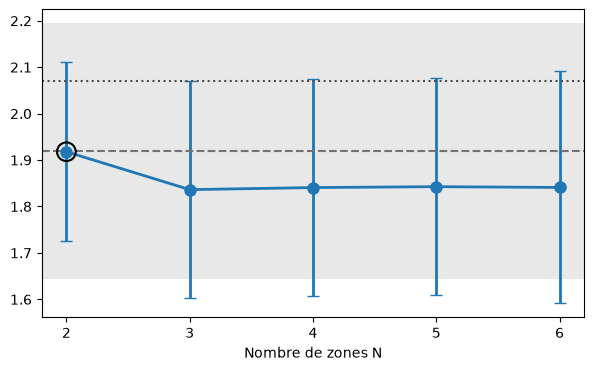

In [57]:
# RMSE (meilleur essai) en fonction de N, avec barres d'erreur = erreur standard sur les plis
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    summary.index,
    summary["rmse"],
    yerr=summary["rmse_se"],
    fmt="o-",
    color="tab:blue",
    linewidth=2,
    markersize=8,
    capsize=4,
    label="Zones optimisées",
)
ax.axhline(
    REFERENCE_RMSE,
    color="0.45",
    linestyle="--",
    linewidth=1.5,
    label="HEART_RATE_ZONES (référence)",
)
ax.axhspan(
    REFERENCE_RMSE - REFERENCE_SE,
    REFERENCE_RMSE + REFERENCE_SE,
    color="0.85",
    alpha=0.6,
    linewidth=0,
)
ax.axhline(
    one_se_threshold, color="0.3", linestyle=":", linewidth=1.5, label="Seuil 1-SE"
)
ax.scatter(
    [SELECTED_N],
    [summary.at[SELECTED_N, "rmse"]],
    s=180,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=3,
    label=f"N retenu = {SELECTED_N}",
)
ax.set_xticks(summary.index)
ax.set_xlabel("Nombre de zones N")
ax.set_ylabel(f"RMSE ({dataset.target_name}), GroupKFold({config.n_splits})")
ax.set_title("RMSE en fonction du nombre de zones cardiaques")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()